# Introduction to Machine Learning – Lab 3
## PCA and k-Means Clustering of the Ames Housing Dataset

### Objective
This notebook prepares the cleaned Ames Housing data for unsupervised learning: the categorical features are encoded, the missing values are filled and all columns are brought to a common scale. It then reduces the data with PCA and groups the houses with k-means.

In [1]:
import sys
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter
from preprocessing import ORDINAL, drop_incomplete, fill_missing, make_preprocessor, make_scaler, prepare_data
from sklearn.decomposition import PCA

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

BLUE, ORANGE = "#86b6ef", "#eb6834"
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"

X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
encoded = make_preprocessor("onehot", min_frequency=5).fit_transform(X, y)

print(f"{len(X):,} houses, {X.shape[1]} features, {encoded.shape[1]} columns after encoding")

2,925 houses, 72 features, 205 columns after encoding


### 1. Encoding of the categorical features

In [2]:
nominal = list(X.select_dtypes("category").columns)
ordinal = [col for col in X.columns if col in ORDINAL]
numeric = [col for col in X.columns if col not in nominal + ordinal]
onehot = [col for col in encoded.columns if col not in X.columns]

summary = pd.DataFrame(
    {
        "Feature type": ["Nominal", "Ordinal", "Discrete and continuous"],
        "Features": [len(nominal), len(ordinal), len(numeric)],
        "Encoding": ["One-hot", "Integers in natural order", "Unchanged"],
        "Columns produced": [len(onehot), len(ordinal), len(numeric)],
    }
)
assert summary["Features"].sum() == X.shape[1]
assert summary["Columns produced"].sum() == encoded.shape[1]

summary.loc[len(summary)] = ["Total", X.shape[1], "", encoded.shape[1]]
display(summary)

,Feature type,Features,Encoding,Columns produced
0,Nominal,18,One-hot,151
1,Ordinal,21,Integers in natural order,21
2,Discrete and continuous,33,Unchanged,33
3,Total,72,,205


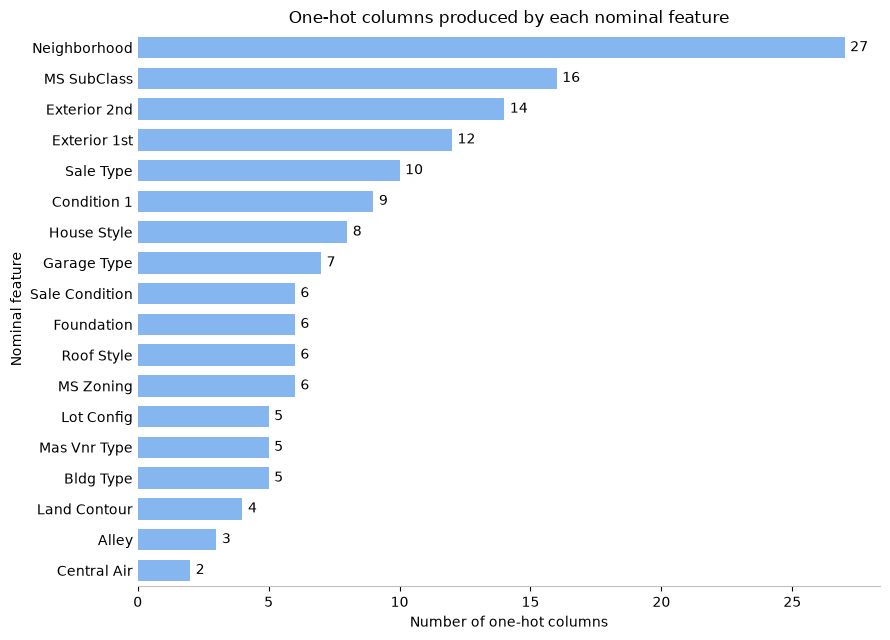

In [3]:
columns_per_feature = pd.Series(
    {feature: sum(col.startswith(f"{feature}_") for col in onehot) for feature in nominal}
).sort_values()
assert columns_per_feature.sum() == len(onehot)

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(columns_per_feature.index, columns_per_feature.values, height=0.7, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set_title("One-hot columns produced by each nominal feature", fontsize=12)
ax.set_xlabel("Number of one-hot columns")
ax.set_ylabel("Nominal feature")
ax.margins(y=0.01)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

#### Interpretation of the encoding
- **Nominal features** have no real order: the neighborhood `NAmes` is neither more nor less than `OldTown`. One integer per category would invent an order and distances that do not exist, so one-hot encoding gives every category its own 0/1 column. Categories found in fewer than 5 houses share one `infrequent` column.
- **Ordinal features** do have a real order, which is kept as integers, for example `Kitchen Qual`: Po < Fa < TA < Gd < Ex. The integers also assume equal gaps between grades: going from Po to Fa counts as much as going from Gd to Ex.
- **`MS SubClass`** looks numeric, but its codes (20, 60, ...) name dwelling types and are not quantities. `clean()` therefore turns it into text, and it is one-hot encoded like the other nominal features (16 columns).
- **Dimensions:** PCA will start from 205 columns rather than 72, and 151 of them are one-hot columns.

### 2. Missing values

In [4]:
gaps_per_house = X.isna().sum(axis=1)
gaps_per_column = X.isna().sum()
gaps_per_column = gaps_per_column[gaps_per_column > 0].sort_values(ascending=False)

houses_by_gaps = gaps_per_house.value_counts().sort_index().rename_axis("Empty cells").to_frame("Houses")
columns_with_gaps = gaps_per_column.rename_axis("Column").to_frame("Empty cells")
assert houses_by_gaps["Houses"].sum() == len(X)
assert columns_with_gaps["Empty cells"].sum() == gaps_per_house.sum()

display(houses_by_gaps)
print(f"{len(columns_with_gaps)} columns hold {gaps_per_column.sum()} empty cells")
display(columns_with_gaps)

,Houses
Empty cells,
0,2281
1,630
2,12
6,1
11,1


19 columns hold 671 empty cells


,Empty cells
Column,
Lot Frontage,490
Garage Yr Blt,159
Bsmt Exposure,4
Garage Finish,2
BsmtFin Type 2,2
Bsmt Cond,1
Bsmt Qual,1
BsmtFin SF 2,1
Bsmt Unf SF,1


In [5]:
X_complete, y_complete = drop_incomplete(X, y)
X_complete = fill_missing(X_complete)
encoded_complete = make_preprocessor("onehot", min_frequency=5).fit_transform(X_complete, y_complete)

assert X_complete.isna().sum().sum() == 0
assert encoded_complete.columns.equals(encoded.columns)

print(f"{len(X_complete):,} houses, {X_complete.isna().sum().sum()} empty cells")
print(f"{encoded_complete.shape[1]} columns after encoding, the same as before")

2,923 houses, 0 empty cells
205 columns after encoding, the same as before


In [6]:
kept = X.loc[X_complete.index]
dropped_gaps = gaps_per_house.drop(kept.index).sort_values(ascending=False)
incomplete = (gaps_per_house > 0).sum()

garage_gap = kept["Garage Yr Blt"].isna()
garage_years = kept.loc[~garage_gap, ["Garage Yr Blt", "Year Built"]]
no_garage = (kept.loc[garage_gap, "Garage Type"] == "NA").sum()
same_year = (garage_years["Garage Yr Blt"] == garage_years["Year Built"]).mean()
correlation = garage_years["Garage Yr Blt"].corr(garage_years["Year Built"], method="spearman")

neighborhood_median = kept.groupby("Neighborhood", observed=True)["Lot Frontage"].transform("median")
no_known_frontage = kept["Lot Frontage"].isna() & neighborhood_median.isna()
other_gaps = kept.drop(columns=["Garage Yr Blt", "Lot Frontage"]).isna().sum().sum()
neighborhoods = sorted(kept.loc[no_known_frontage, "Neighborhood"].astype(str).unique())

oldest_garage = garage_years["Garage Yr Blt"].min()
filled_years = X_complete.loc[garage_gap, "Garage Yr Blt"]

print(f"Houses dropped: {len(dropped_gaps)}")
for house, count in dropped_gaps.items():
    print(f"  {count} empty cells: {', '.join(X.columns[X.loc[house].isna()])}")
print(f"Most empty cells in a kept house: {gaps_per_house[kept.index].max()}")
print(f"Houses with any empty cell: {incomplete} ({incomplete / len(X):.1%})")
print(f"Empty garage years in the kept houses: {garage_gap.sum()}, of which without a garage: {no_garage}")
print(f"Known garage years equal to Year Built: {same_year:.1%}")
print(f"Spearman correlation of Garage Yr Blt and Year Built: {correlation:.2f}")
print(
    f"Lot Frontage medians by neighborhood: {neighborhood_median.min():.0f} to {neighborhood_median.max():.0f}, "
    f"overall median: {kept['Lot Frontage'].median():.0f}"
)
print(f"Cells filled with the plain median: {other_gaps + no_known_frontage.sum()}")
print(f"Of these Lot Frontage cells: {no_known_frontage.sum()}, in {', '.join(neighborhoods)}")
print(f"Oldest known garage: {oldest_garage:.0f}, oldest filled year: {filled_years.min():.0f}")
print(f"Filled years older than the oldest known garage: {(filled_years < oldest_garage).sum()}")

Houses dropped: 2
  11 empty cells: Bsmt Qual, Bsmt Cond, Bsmt Exposure, BsmtFin Type 1, BsmtFin SF 1, BsmtFin Type 2, BsmtFin SF 2, Bsmt Unf SF, Total Bsmt SF, Bsmt Full Bath, Bsmt Half Bath
  6 empty cells: Garage Yr Blt, Garage Finish, Garage Cars, Garage Area, Garage Qual, Garage Cond
Most empty cells in a kept house: 2
Houses with any empty cell: 644 (22.0%)
Empty garage years in the kept houses: 158, of which without a garage: 157
Known garage years equal to Year Built: 80.3%
Spearman correlation of Garage Yr Blt and Year Built: 0.90
Lot Frontage medians by neighborhood: 21 to 92, overall median: 68
Cells filled with the plain median: 9
Of these Lot Frontage cells: 3, in GrnHill, Landmrk
Oldest known garage: 1895, oldest filled year: 1872
Filled years older than the oldest known garage: 4


#### Interpretation of the missing values
- **Why they are filled:** PCA and k-means calculate with every cell of a house, so they cannot run with empty cells. XGBoost can, which is why `clean()` left them in place.
- **Two houses are dropped:** one has 11 empty cells, its whole basement block, and the other has 6, its whole garage block. Every other house has at most 2. Dropping every incomplete house instead would lose 644 houses (22.0%).
- **`Garage Yr Blt`** is empty mostly because there is no garage: this is true for 157 of the 158 empty cells left. No real year exists for these houses, so `Year Built` is only the closest stand-in. Where the garage year is known, it equals `Year Built` for 80.3% of the houses, and the Spearman correlation of the two columns is 0.90.
- **`Lot Frontage`** is truly unknown: these houses do have a lot, but its frontage was not recorded. The neighborhood median is closer than the overall median, because the medians of the neighborhoods range from 21 to 92 feet, while the overall median is 68.
- **Remaining cells:** the last 9 cells are too few to matter and get the plain median of their column. 3 of them are `Lot Frontage` cells in `GrnHill` and `Landmrk`, which have no known frontage to take a median from.
- **Order:** the fill happens before scaling because 4 filled years are older than the oldest known garage. They lower the minimum of `Garage Yr Blt` from 1895 to 1872, and the scaler has to see this final minimum.

### 3. Min-max scaling

In [7]:
# Fitted on all houses: k-means has no train/test split
scaled = make_scaler().fit_transform(encoded_complete)

empty_cells = scaled.isna().sum().sum()
onehot_unchanged = scaled[onehot].equals(encoded_complete[onehot])

# allclose: the largest value of a column can land a rounding error away from 1
assert np.allclose(scaled.min(), 0) and np.allclose(scaled.max(), 1)
assert empty_cells == 0
assert onehot_unchanged

print(f"Range of all {scaled.shape[1]} columns: {scaled.min().min():.0f} to {scaled.max().max():.0f}")
print(f"Empty cells after scaling: {empty_cells}")
print(f"One-hot columns unchanged: {onehot_unchanged}")

Range of all 205 columns: 0 to 1
Empty cells after scaling: 0
One-hot columns unchanged: True


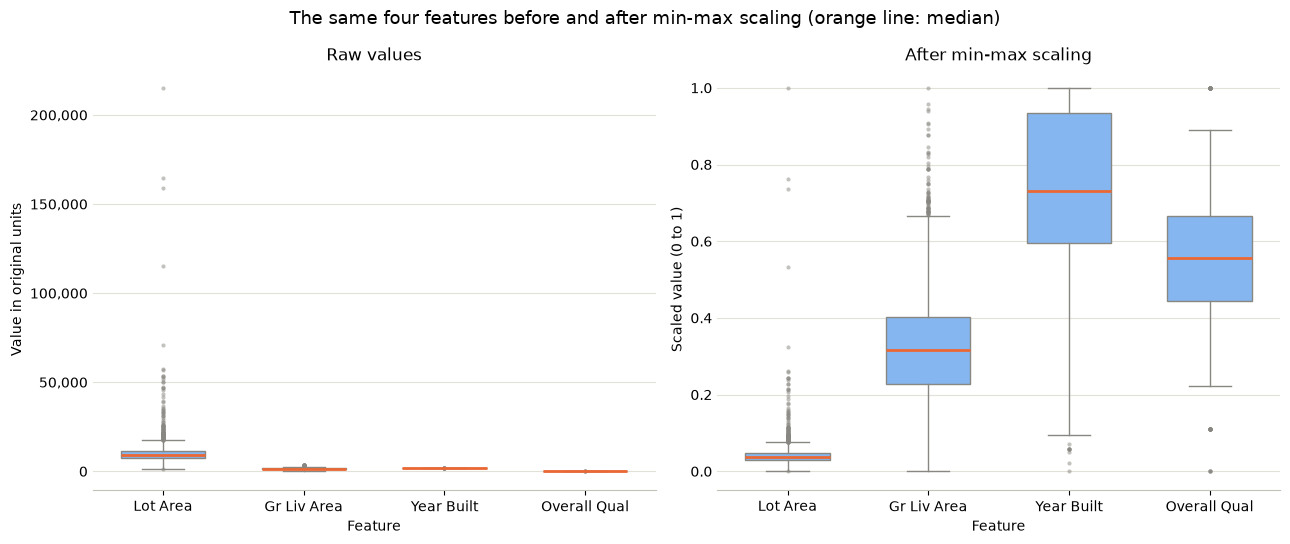

In [8]:
features = ["Lot Area", "Gr Liv Area", "Year Built", "Overall Qual"]
panels = [
    (encoded_complete, "Raw values", "Value in original units"),
    (scaled, "After min-max scaling", "Scaled value (0 to 1)"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (data, title, ylabel) in zip(axes, panels):
    ax.boxplot(
        [data[feature] for feature in features],
        tick_labels=features,
        widths=0.6,
        patch_artist=True,
        boxprops={"facecolor": BLUE, "edgecolor": MUTED},
        whiskerprops={"color": MUTED},
        capprops={"color": MUTED},
        medianprops={"color": ORANGE, "linewidth": 2},
        flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none", "alpha": 0.5},
    )
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Feature")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="y", length=0)

axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.suptitle("The same four features before and after min-max scaling (orange line: median)", fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
variance = encoded_complete.var()
lot_area = scaled["Lot Area"]

print(f"Share of Lot Area in the total raw variance: {variance['Lot Area'] / variance.sum():.1%}")
print(f"Largest raw Lot Area: {encoded_complete['Lot Area'].max():,.0f}")
print(f"Houses with a scaled Lot Area below 0.1: {(lot_area < 0.1).mean():.1%}")
print(f"Median scaled Lot Area: {lot_area.median():.3f}")

Share of Lot Area in the total raw variance: 97.6%
Largest raw Lot Area: 215,245
Houses with a scaled Lot Area below 0.1: 98.1%
Median scaled Lot Area: 0.038


#### Interpretation of the min-max scaling
- **Formula:** every column is transformed with `(x - min) / (max - min)`, using the minimum and maximum of that column.
- **Range:** every feature ends up between 0 and 1. The smallest value of a column becomes 0 and the largest becomes 1.
- **Order:** the formula only shifts and stretches a column, so the order of the houses within a feature does not change, and neither does the shape of its distribution.
- **One-hot columns** stay 0/1, because their minimum is already 0 and their maximum already 1.
- **Why it is needed:** distances and variance otherwise follow the features with the largest numbers. Raw `Lot Area` holds 97.6% of the total variance, so a distance between two houses would mostly be a difference in lot size. In the left panel, `Year Built` and `Overall Qual` shrink to flat lines next to it.
- **Sensitivity to outliers:** the minimum and maximum are set by the most extreme houses alone. `Lot Area` reaches 215,245, so 98.1% of the houses land below 0.1 and the median is only 0.038. The feature is on the same scale as the others, but almost all of its houses sit in the lowest tenth of that scale, as the right panel shows.

### 4. Principal component analysis

In [10]:
# One fit is enough: the components kept at a lower threshold are the first ones of this fit
pca = PCA(n_components=0.98, svd_solver="full")
reduced = pca.fit_transform(scaled)
shares = pca.explained_variance_ratio_
cumulative = shares.cumsum()
thresholds = [0.98, 0.95, 0.90, 0.80]
component_counts = {t: int(np.searchsorted(cumulative, t) + 1) for t in thresholds}

above_one_percent = shares > 0.01
assert component_counts[0.98] == pca.n_components_ == reduced.shape[1]

print(f"Columns before / after PCA: {scaled.shape[1]} / {reduced.shape[1]}")
print(f"Variance kept: {cumulative[-1]:.2%}")
print("Shares of the first ten components:")
for number, share in enumerate(shares[:10], start=1):
    print(f"  PC{number}: {share:.2%}")
print(f"First ten components together: {cumulative[9]:.2%}")
print(f"Share of the last component: {shares[-1]:.2%}")
print(f"Components explaining more than 1%: {above_one_percent.sum()}, together {shares[above_one_percent].sum():.2%}")

Columns before / after PCA: 205 / 113
Variance kept: 98.04%
Shares of the first ten components:
  PC1: 13.40%
  PC2: 8.86%
  PC3: 5.50%
  PC4: 4.22%
  PC5: 3.60%
  PC6: 3.05%
  PC7: 2.94%
  PC8: 2.86%
  PC9: 2.78%
  PC10: 2.44%
First ten components together: 49.66%
Share of the last component: 0.06%
Components explaining more than 1%: 25, together 71.74%


In [11]:
counts = list(component_counts.values())
variance_table = pd.DataFrame(
    {
        "Variance kept": [f"{t:.0%}" for t in thresholds],
        "Components": counts,
        "Share of the columns": [f"{count / scaled.shape[1]:.1%}" for count in counts],
    }
)
display(variance_table)
print(f"Extra components from 80% to 98%: {component_counts[0.98] - component_counts[0.80]}")

,Variance kept,Components,Share of the columns
0,98%,113,55.1%
1,95%,82,40.0%
2,90%,59,28.8%
3,80%,36,17.6%


Extra components from 80% to 98%: 77


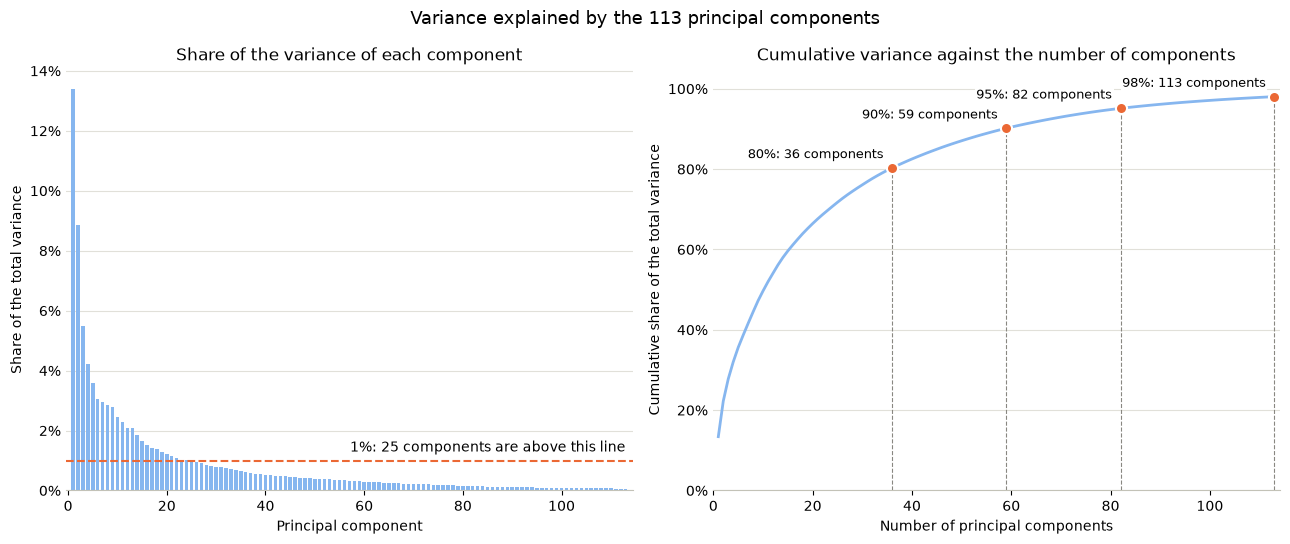

In [12]:
numbers = np.arange(1, len(shares) + 1)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5))

left.bar(numbers, shares, width=0.7, color=BLUE)
left.axhline(0.01, color=ORANGE, linewidth=1.5, linestyle="--")
left.text(numbers[-1], 0.013, f"1%: {above_one_percent.sum()} components are above this line", ha="right")
left.set_title("Share of the variance of each component", fontsize=12)
left.set_xlabel("Principal component")
left.set_ylabel("Share of the total variance")
left.margins(x=0.01)

right.plot(numbers, cumulative, color=BLUE, linewidth=2)
for threshold, count in component_counts.items():
    kept_share = cumulative[count - 1]
    right.vlines(count, 0, kept_share, color=MUTED, linewidth=0.8, linestyle="--")
    right.plot(count, kept_share, "o", color=ORANGE, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
    right.annotate(
        f"{threshold:.0%}: {count} components",
        (count, kept_share),
        xytext=(-6, 7),
        textcoords="offset points",
        ha="right",
        fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
right.set_title("Cumulative variance against the number of components", fontsize=12)
right.set_xlabel("Number of principal components")
right.set_ylabel("Cumulative share of the total variance")
right.set_ylim(0, 1.05)
right.margins(x=0.01)

for ax in (left, right):
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0%}"))
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="y", length=0)

fig.suptitle(f"Variance explained by the {len(shares)} principal components", fontsize=13)
plt.tight_layout()
plt.show()

#### Interpretation of the principal components
- **What 98% means:** the reduced data keeps 98% of the original differences between the houses and loses 2% of them. It does not mean that the houses differ by 98%. The components kept reach 98.04%, slightly above the threshold.
- **Features left:** the data goes from 205 columns to 113 (55.1%). Each component is a weighted mix of all 205 columns, so these are 113 new columns, and no original column is simply kept.
- **How quickly the shares fall:** PC1 explains 13.40%, PC2 8.86% and PC3 5.50%. By PC10 the share is down to 2.44%, the first ten components together hold 49.66%, and the last component adds only 0.06%.
- **Components above 1%:** only 25 of the 113 components explain more than 1%, together 71.74%. All the others add less than 1% each, which is the long flat tail in the left panel.
- **Cost of a higher threshold:** 80% takes 36 components, 90% takes 59, 95% takes 82 and 98% takes 113. Going from 80% to 98% takes 77 more components, over twice as many as the first 80% needed, because each later component adds less. The curve in the right panel flattens for the same reason.